Albedo 数据统计：
count    82482.000000
mean         0.657968
std          0.210738
min          0.149082
25%          0.455501
50%          0.772323
75%          0.840841
max          0.907045
Name: albedo, dtype: float64


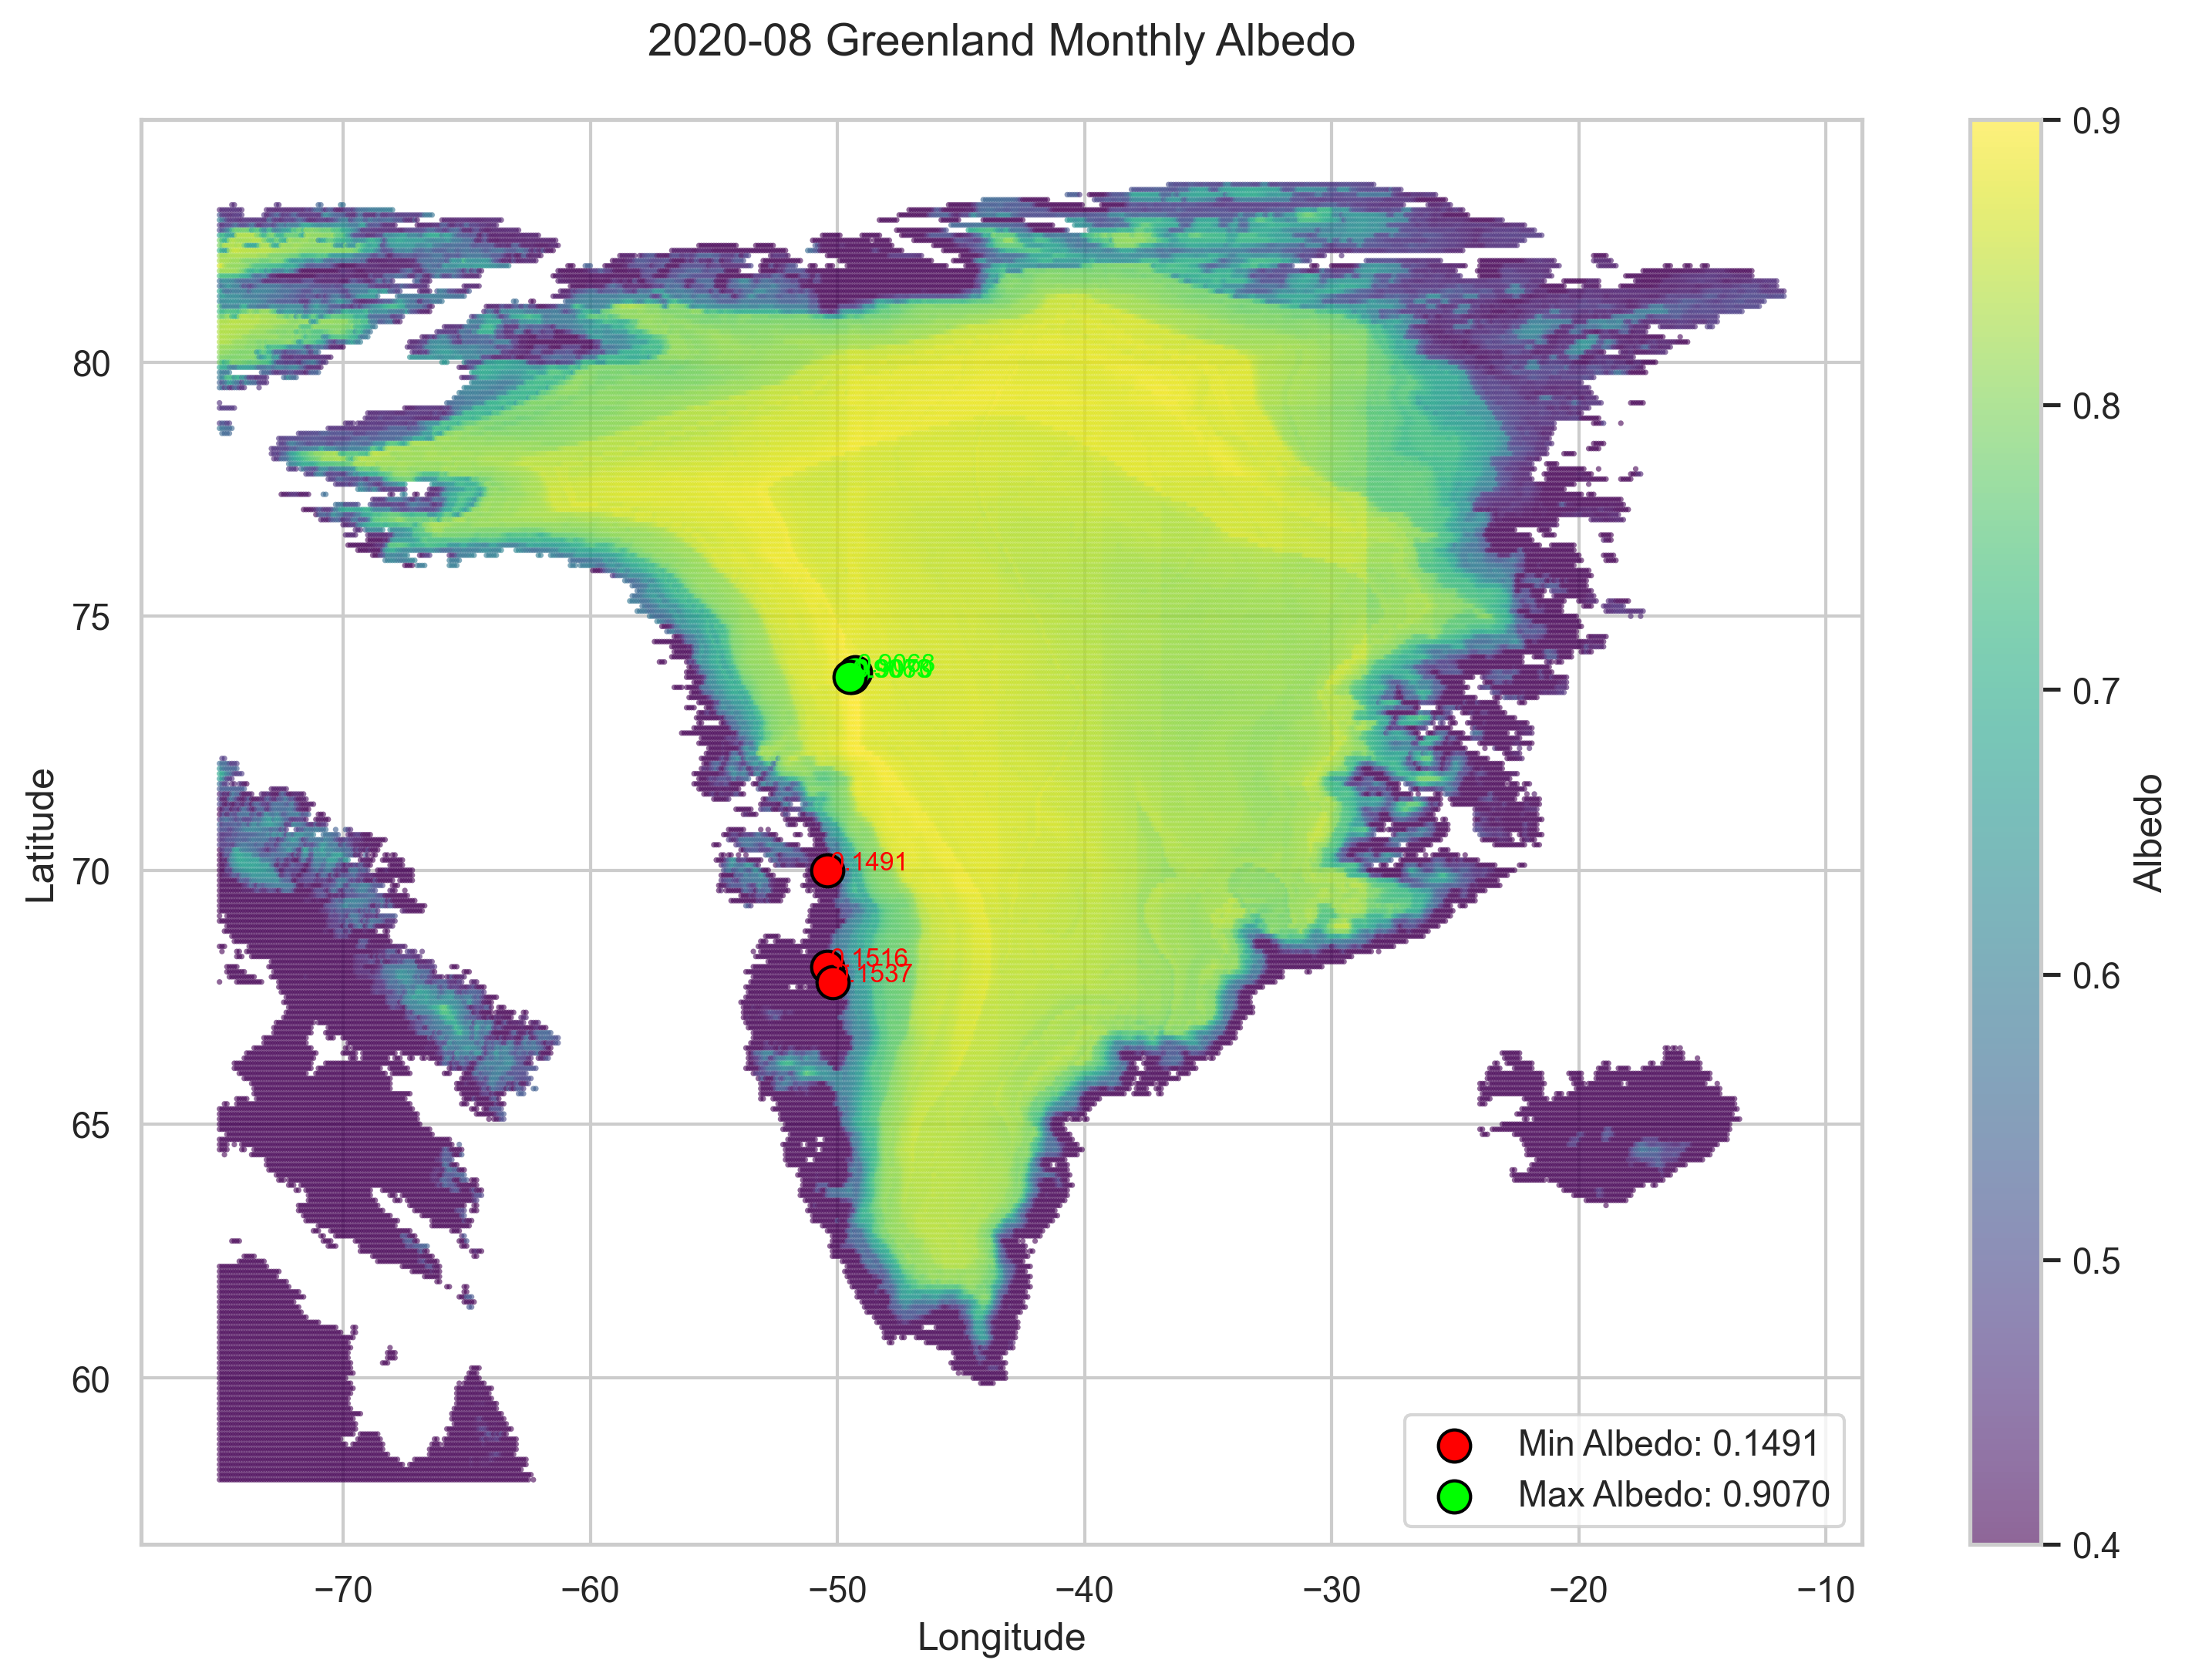

高分辨率图片已保存至：F:\TUB\greenlandProject\ERA5LAND\beifen\Greenland_Albedo_202008.png


<Figure size 640x480 with 0 Axes>

In [3]:
#---------------------------------------模型推理2020年8月的albedo模型和------------------------极值显示-------------------------------
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. 读取数据
csv_file_path = r'F:\TUB\greenlandProject\ERA5LAND\beifen\202008train_with_albedo.csv'
df = pd.read_csv(csv_file_path)

# 检查数据范围
print("Albedo 数据统计：")
print(df['albedo'].describe())

# 2. 设置绘图样式
sns.set(style="whitegrid")

# 3. 绘制散点图（优化对比度）
plt.figure(figsize=(12, 8), dpi=300)  # 提高初始画布分辨率
scatter = plt.scatter(
    df['longitude'], 
    df['latitude'], 
    c=df['albedo'], 
    cmap='viridis',  # 高对比度色图
    s=3,            # 更小的点
    alpha=0.6,      # 适当透明度
    edgecolor='none', 
    vmin=0.4,       # 调整最小值
    vmax=0.9        # 调整最大值
)

# 4. 添加颜色条
cbar = plt.colorbar(scatter, label='Albedo')
cbar.set_ticks([0.4, 0.5, 0.6, 0.7, 0.8, 0.9])

# 5. 找到最低的三个值和最高的三个值
lowest_3 = df.nsmallest(3, 'albedo')    # 最低的3个点
highest_3 = df.nlargest(3, 'albedo')    # 最高的3个点

# 6. 标注最低的三个值（红色）
for idx, row in lowest_3.iterrows():
    plt.scatter(
        row['longitude'], 
        row['latitude'], 
        color='red', 
        s=100,          # 较大的点
        edgecolor='black',
        label=f'Min Albedo: {row["albedo"]:.4f}' if idx == lowest_3.index[0] else ""
    )
    plt.text(
        row['longitude'] + 0.1, 
        row['latitude'], 
        f'{row["albedo"]:.4f}', 
        fontsize=8, 
        color='red',
        ha='left'
    )

# 7. 标注最高的三个值（绿色）
for idx, row in highest_3.iterrows():
    plt.scatter(
        row['longitude'], 
        row['latitude'], 
        color='lime', 
        s=100, 
        edgecolor='black',
        label=f'Max Albedo: {row["albedo"]:.4f}' if idx == highest_3.index[0] else ""
    )
    plt.text(
        row['longitude'] + 0.1, 
        row['latitude'], 
        f'{row["albedo"]:.4f}', 
        fontsize=8, 
        color='lime',
        ha='left'
    )

# 8. 设置标题和标签
plt.title('2020-08 Greenland Monthly Albedo', fontsize=14, pad=20)  # 更新标题
plt.xlabel('Longitude', fontsize=12)
plt.ylabel('Latitude', fontsize=12)
plt.legend()

# 9. 显示图表
plt.show()

# 10. 保存高分辨率图片（300 dpi）
output_path = r'F:\TUB\greenlandProject\ERA5LAND\beifen\Greenland_Albedo_202008.png'  # 使用原始字符串
# 或
output_path = 'F:\\TUB\\greenlandProject\\ERA5LAND\\beifen\\Greenland_Albedo_202008.png'  # 转义反斜杠

plt.savefig(
    output_path,
    dpi=300,          
    bbox_inches='tight',  
    facecolor='white'     
)
print(f"高分辨率图片已保存至：{output_path}")

In [2]:
#----------------------------月均值计算-----------格陵兰所有区域-------------------有年变化---------------------------
import os
import pandas as pd

# 设置CSV文件所在路径
folder_path = r'F:\TUB\greenlandProject\ne_10m_admin_0_countries\greenlandAlbedo'

# 初始化结果列表
results = []

# 遍历文件夹中的所有CSV文件
for filename in os.listdir(folder_path):
    if filename.endswith('.csv'):
        file_path = os.path.join(folder_path, filename)
        
        try:
            # 读取CSV文件
            df = pd.read_csv(file_path)
            
            # 检查是否包含'albedo'列
            if 'albedo' in df.columns:
                # 计算均值
                mean_albedo = df['albedo'].mean()
                
                # 提取文件名前面的年月部分（如195009）
                time = filename[:6]
                
                # 记录结果
                results.append({'time': time, 'albedo_mean': mean_albedo})
            else:
                print(f"文件缺少'albedo'列: {filename}")
        except Exception as e:
            print(f"无法读取文件 {filename}: {e}")

# 将结果转为DataFrame并按时间排序
mean_df = pd.DataFrame(results)
mean_df = mean_df.sort_values(by='time')

# 保存为mean.csv
output_path = os.path.join(folder_path, 'mean.csv')
mean_df.to_csv(output_path, index=False)

print(f"完成！均值文件已保存至: {output_path}")


完成！均值文件已保存至: F:\TUB\greenlandProject\ne_10m_admin_0_countries\greenlandAlbedo\mean.csv


In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from tqdm import tqdm

def process_directory(path, selected_years_months=None):
    """
    处理目录中的CSV文件，跳过已存在的图片
    :param path: 目录路径
    :param selected_years_months: 可选，指定要处理的年月列表
    """
    
    # 创建输出目录
    output_dir = os.path.join(path, 'pic')
    os.makedirs(output_dir, exist_ok=True)
    
    # 获取所有以19或20开头的CSV文件
    all_files = sorted([f for f in os.listdir(path) 
                      if (f.startswith('19') or f.startswith('20')) and f.endswith('.csv')])
    
    # 过滤指定的年月
    if selected_years_months:
        files_to_process = [f for f in all_files 
                          if any(f.startswith(ym) for ym in selected_years_months)]
    else:
        files_to_process = all_files
    
    print(f"找到 {len(files_to_process)} 个符合条件的CSV文件")
    
    # 过滤已处理的文件
    processed_files = set()
    if os.path.exists(output_dir):
        processed_files = {f.replace('_heatmap.png', '.csv') 
                         for f in os.listdir(output_dir) if f.endswith('_heatmap.png')}
    
    files_to_process = [f for f in files_to_process if f not in processed_files]
    
    print(f"已处理 {len(processed_files)} 个，剩余 {len(files_to_process)} 个待处理")
    
    if not files_to_process:
        print("没有需要处理的文件")
        return
    
    # 固定albedo范围0-1，间隔0.1
    vmin, vmax = 0.0, 1.0
    ticks = [i/10 for i in range(11)]  # [0.0, 0.1, ..., 1.0]
    
    # 处理每个文件
    for filename in tqdm(files_to_process, desc="生成热力图中"):
        filepath = os.path.join(path, filename)
        try:
            df = pd.read_csv(filepath)
            
            # 检查必要的列
            if not all(col in df.columns for col in ['latitude', 'longitude', 'albedo']):
                print(f"跳过 {filename} (缺少必要列)")
                continue
                
            # 确保albedo在0-1范围内
            df['albedo'] = df['albedo'].clip(lower=vmin, upper=vmax)
                
            # 生成热力图
            plot_heatmap(df, filename, output_dir, vmin, vmax, ticks)
            
        except Exception as e:
            print(f"处理 {filename} 时出错: {str(e)}")
            continue

def plot_heatmap(df, filename, output_dir, vmin, vmax, ticks):
    """
    生成热力图并保存(使用固定颜色范围)
    :param df: 数据DataFrame
    :param filename: 原始文件名
    :param output_dir: 输出目录
    :param vmin: 颜色映射最小值(0)
    :param vmax: 颜色映射最大值(1)
    :param ticks: 色标刻度位置
    """
    plt.figure(figsize=(12, 8))
    
    # 创建离散化的颜色映射
    cmap = plt.get_cmap('coolwarm')
    norm = mcolors.Normalize(vmin=vmin, vmax=vmax)
    
    scatter = plt.scatter(
        x=df['longitude'],
        y=df['latitude'],
        c=df['albedo'],
        cmap=cmap,
        norm=norm,  # 应用统一的范围标准化
        s=10,
        alpha=0.7,
        edgecolors='none'
    )
    
    # 添加颜色条
    cbar = plt.colorbar(scatter, ticks=ticks)
    cbar.set_label('Albedo Value', rotation=270, labelpad=20)
    
    # 设置标题和标签
    yyyymm = filename.split('.')[0]
    plt.title(f'Greenland {yyyymm} Monthly Albedo', fontsize=14)
    plt.xlabel('Longitude', fontsize=12)
    plt.ylabel('Latitude', fontsize=12)
    
    plt.tight_layout()
    
    # 保存图片
    output_filename = os.path.join(output_dir, f"{yyyymm}_heatmap.png")
    plt.savefig(output_filename, dpi=300, bbox_inches='tight')
    plt.close()

if __name__ == "__main__":
    path = r"E:\TUB\greenland\1995bu"
    selected_years_months = None  # 例如: ['199501', '199502']
    
    process_directory(path, selected_years_months)
    print("处理完成!")

找到 450 个符合条件的CSV文件
已处理 450 个，剩余 0 个待处理
没有需要处理的文件
处理完成!


=== JJA (6–8月) 空间平均『夏季总量』 — 单位：mm（前10行预览）===
             tp         sf    rf
year                            
1950  31.200001  25.610001  5.59
1951  34.299999  26.799999  7.50
1952  37.470001  29.740000  7.73
1953  39.799999  33.450001  6.35
1954  49.540001  41.630001  7.91
1955  46.860001  40.270000  6.58
1956  31.719999  27.010000  4.71
1957  26.010000  21.290001  4.72
1958  27.350000  22.860001  4.49
1959  34.779999  28.910000  5.86


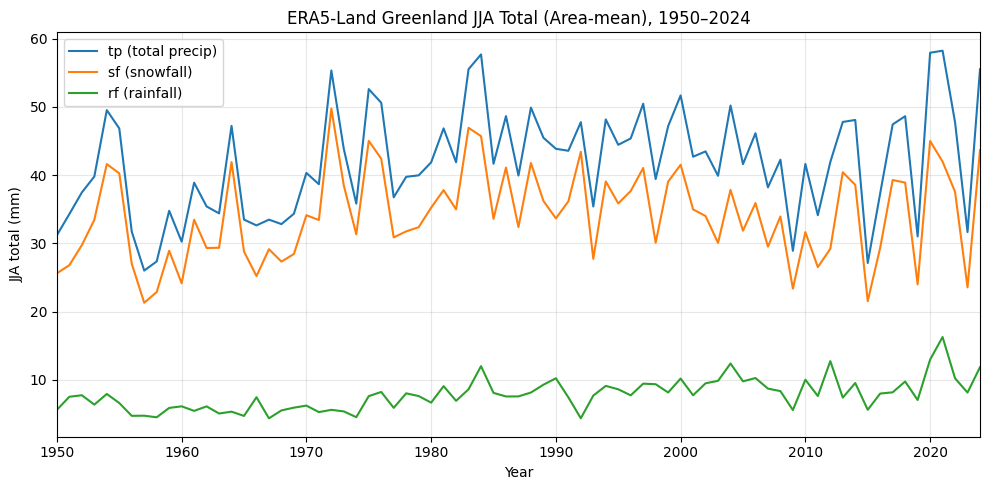

In [16]:
# -*- coding: utf-8 -*-
import xarray as xr
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ========= 可修改 =========
NC_PATH     = r"E:\TUB\greenland\sf_tp_rf.nc"
TIME_DIM    = "valid_time"     # 若文件里是 'time' 会自动兼容
START_YEAR  = 1950
END_YEAR    = 2024
# =========================

# 读取数据
ds = xr.open_dataset(NC_PATH)

# 兼容时间维名称
if TIME_DIM not in ds.dims:
    if "time" in ds.dims:
        ds = ds.rename({"time": TIME_DIM})
        TIME_DIM = "valid_time" if "valid_time" in ds.coords else "time"
    else:
        raise ValueError(f"未找到时间维度：{TIME_DIM} 或 'time'")

# 若 rf 不存在则计算
if "rf" not in ds.data_vars and all(v in ds.data_vars for v in ("tp", "sf")):
    ds["rf"] = ds["tp"] - ds["sf"]
    ds["rf"].attrs.update(units=ds["tp"].attrs.get("units", "m"),
                          long_name="Rainfall (tp - sf)")

vars_to_use = [v for v in ["tp", "sf", "rf"] if v in ds.data_vars]
if not vars_to_use:
    raise ValueError("文件中没有 tp/sf/rf 变量。")

# 子集年份范围（若数据不含这么早的年份，会自动按可用范围截断）
t0 = f"{START_YEAR}-01-01"
t1 = f"{END_YEAR}-12-31"
ds = ds.sel({TIME_DIM: slice(t0, t1)})

# 构造每个 time 的“当月天数”数组
time_index = pd.to_datetime(ds[TIME_DIM].values)
days_in_month = pd.DatetimeIndex(time_index).days_in_month.astype("float32")
days_da = xr.DataArray(days_in_month, coords={TIME_DIM: ds[TIME_DIM]}, dims=[TIME_DIM])

# 月均值(m) → 月总量(m)
totals_m = {
    v: (ds[v] * days_da).assign_attrs(
        units="m",
        long_name=f"{v} monthly total (mean × days_in_month)"
    )
    for v in vars_to_use
}

# 取 JJA（三个月）
is_jja = xr.DataArray(
    np.isin(pd.DatetimeIndex(time_index).month, [6, 7, 8]),
    coords={TIME_DIM: ds[TIME_DIM]},
    dims=[TIME_DIM]
)
jja = {v: totals_m[v].where(is_jja, drop=True) for v in vars_to_use}

# 按年份对 JJA 求和（得到“夏季总量(m)”）
for v in vars_to_use:
    jja[v] = jja[v].groupby(getattr(jja[v][TIME_DIM].dt, "year")).sum(TIME_DIM)

# 空间平均（你也可以改成 .max / .min 看极值）
def spatial_mean(da):
    spatial_dims = [d for d in da.dims if d != "year"]
    return da.mean(dim=spatial_dims)

jja_mean_m = {v: spatial_mean(jja[v]) for v in vars_to_use}
jja_mean_mm = {v: (jja_mean_m[v] * 1000.0).assign_attrs(units="mm") for v in vars_to_use}

# 组织为 DataFrame 方便画图/检查
years = jja_mean_mm[vars_to_use[0]]["year"].values
df_mm = pd.DataFrame({v: jja_mean_mm[v].values for v in vars_to_use}, index=years)
df_mm.index.name = "year"

print("=== JJA (6–8月) 空间平均『夏季总量』 — 单位：mm（前10行预览）===")
print(df_mm.head(10).round(2))

# 画折线图（一个图三条线）
plt.figure(figsize=(10, 5))
plt.plot(df_mm.index, df_mm["tp"], label="tp (total precip)")
plt.plot(df_mm.index, df_mm["sf"], label="sf (snowfall)")
plt.plot(df_mm.index, df_mm["rf"], label="rf (rainfall)")
plt.title("ERA5-Land Greenland JJA Total (Area-mean), 1950–2024")
plt.xlabel("Year")
plt.ylabel("JJA total (mm)")
plt.grid(True, alpha=0.3)
plt.xlim(df_mm.index.min(), df_mm.index.max())
plt.legend()
plt.tight_layout()
plt.show()


=== JJA (6–8月) 空间平均 2m 气温 — 单位：°C（前10行预览）===
      t2m_JJA
year         
1950    -2.96
1951    -3.21
1952    -3.33
1953    -3.13
1954    -3.10
1955    -3.52
1956    -3.55
1957    -3.01
1958    -3.78
1959    -3.55


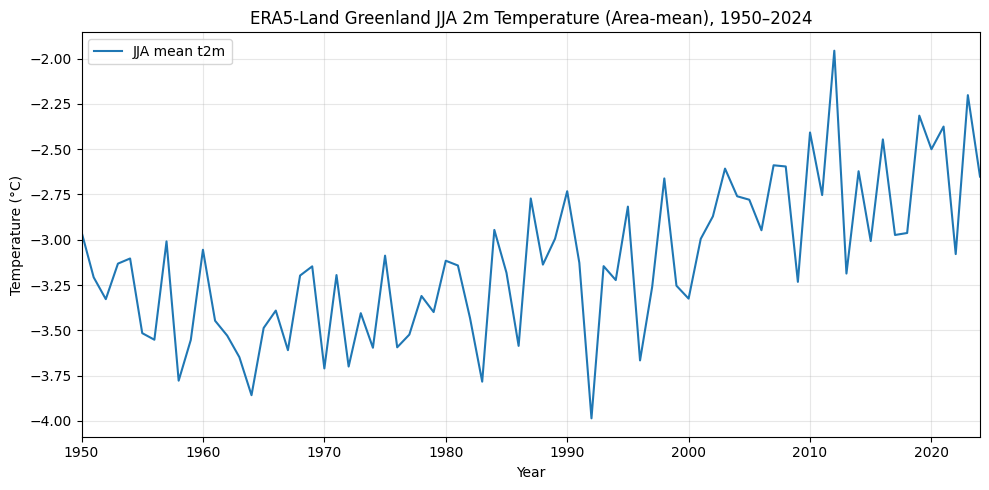

In [18]:
# -*- coding: utf-8 -*-
import xarray as xr
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ========= 可修改 =========
NC_PATH     = r"F:\TUB\greenlandProject\ERA5LAND\ProcessFile\greenlandT2M.nc"
TIME_DIM    = "valid_time"     # 若文件里是 'time' 会自动兼容
START_YEAR  = 1950
END_YEAR    = 2024
TO_CELSIUS  = True             # True: K→°C（t2m-273.15）
# 可选：如果你有陆地掩膜（与格点同维），可在读取后开启
APPLY_MASK  = False
# landmask_path = r"F:\...\landmask.nc"  # 可选：若需要海陆掩膜
# landmask_var  = "mask"                 # 掩膜变量名，1=陆地，0=海洋
# =========================

# 读取数据
ds = xr.open_dataset(NC_PATH)

# 兼容时间维名称
if TIME_DIM not in ds.dims:
    if "time" in ds.dims:
        ds = ds.rename({"time": TIME_DIM})
    else:
        raise ValueError(f"未找到时间维：{TIME_DIM} 或 'time'")

# 检查变量
var_name = "t2m"
if var_name not in ds.data_vars:
    # 有些文件变量名可能不同，请在此改名
    raise ValueError(f"文件中未找到变量 '{var_name}'，请检查变量名。")

# 子集时间范围
t0 = f"{START_YEAR}-01-01"
t1 = f"{END_YEAR}-12-31"
ds = ds.sel({TIME_DIM: slice(t0, t1)})

# 可选：应用海陆掩膜（若需要）
if APPLY_MASK:
    # lm = xr.open_dataset(landmask_path)[landmask_var]
    # ds[var_name] = ds[var_name].where(lm>0.5)
    pass

# 将温度转为 °C（若需要）
t2m = ds[var_name]
if TO_CELSIUS:
    t2m = (t2m - 273.15).assign_attrs(units="degC", long_name="2m temperature (°C)")
else:
    t2m = t2m.assign_attrs(units="K", long_name="2m temperature (K)")

# 每个时间点对应的当月天数（用于加权季平均）
time_index     = pd.to_datetime(ds[TIME_DIM].values)
days_in_month  = pd.DatetimeIndex(time_index).days_in_month.astype("float32")
w_days         = xr.DataArray(days_in_month, coords={TIME_DIM: ds[TIME_DIM]}, dims=[TIME_DIM])

# 仅取 JJA（三个月）
is_jja = xr.DataArray(
    np.isin(pd.DatetimeIndex(time_index).month, [6, 7, 8]),
    coords={TIME_DIM: ds[TIME_DIM]},
    dims=[TIME_DIM]
)
t2m_jja = t2m.where(is_jja, drop=True)
w_jja   = w_days.where(is_jja, drop=True)

# 按年份加权季平均（加权=按各月天数）
# 先对每年求权重之和，再做 (t2m*w).sum / w.sum
year_coord = getattr(t2m_jja[TIME_DIM].dt, "year")
t2m_wsum   = (t2m_jja * w_jja).groupby(year_coord).sum(TIME_DIM)
w_sum      = w_jja.groupby(year_coord).sum(TIME_DIM)
t2m_jja_yearly = (t2m_wsum / w_sum)
t2m_jja_yearly.name = "t2m_JJA_weighted_mean"

# 空间平均（也可改为 .max / .min）
spatial_dims = [d for d in t2m_jja_yearly.dims if d != "year"]
t2m_jja_series = t2m_jja_yearly.mean(dim=spatial_dims)

# 转为 DataFrame 方便查看
years = t2m_jja_series["year"].values
df = pd.DataFrame({"t2m_JJA": t2m_jja_series.values}, index=years)
df.index.name = "year"

print("=== JJA (6–8月) 空间平均 2m 气温 — 单位：{}（前10行预览）===".format(
    "°C" if TO_CELSIUS else "K"
))
print(df.head(10).round(2))

# 画折线图
plt.figure(figsize=(10, 5))
plt.plot(df.index, df["t2m_JJA"], label="JJA mean t2m")
plt.title("ERA5-Land Greenland JJA 2m Temperature (Area-mean), {}–{}".format(
    int(df.index.min()), int(df.index.max())
))
plt.xlabel("Year")
plt.ylabel("Temperature ({})".format("°C" if TO_CELSIUS else "K"))
plt.grid(True, alpha=0.3)
plt.xlim(df.index.min(), df.index.max())
plt.legend()
plt.tight_layout()
plt.show()


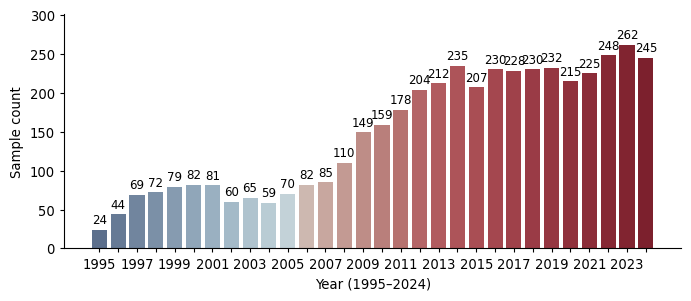

In [5]:
# --- npj-style yearly bar chart (1995–2024) with muted blue→red gradient ---
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, Normalize

# ========= 路径（改成你的） =========
CSV_PATH = r"C:\Users\greenlandProject\ERA5LAND\merged_allfeature.csv"

# ========= 样式 =========
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 9.5,
    "axes.linewidth": 0.8,
    "axes.edgecolor": "black",
    "xtick.direction": "out",
    "ytick.direction": "out",
    "xtick.major.size": 3,
    "ytick.major.size": 3,
    "savefig.dpi": 300,
})

# ========= 读数据 & 拿年份 =========
df = pd.read_csv(CSV_PATH)

year_col = None
for c in ["year","Year","YEAR"]:
    if c in df.columns:
        year_col = c
        break

if year_col is None:
    # 若只有日期列，尝试解析
    for c in df.columns:
        if "date" in c.lower():
            dt = pd.to_datetime(df[c], errors="coerce")
            if dt.notna().sum() > 0:
                df["year"] = dt.dt.year
                year_col = "year"
                break

if year_col is None:
    raise KeyError("未找到年份（year）或可解析的日期列。")

# 仅保留 1995–2024
year_min, year_max = 1995, 2024
df = df[(df[year_col] >= year_min) & (df[year_col] <= year_max)]

# 逐年统计
years = np.arange(year_min, year_max+1)
counts = pd.Series(0, index=years, dtype=int)
counts.update(df[year_col].value_counts().astype(int))

# ========= 低饱和蓝→红渐变 =========
# 手工挑选一组偏灰的蓝到红（长度 30）
palette = [
    "#5C6F8C", "#667A95", "#71859E", "#7B90A7", "#869BB0",
    "#90A6B9", "#9AB0C1", "#A4BAC8", "#AFc3CE", "#B9CCD4",
    "#C3D2D8", "#CDB8B0", "#C8A79F", "#C39A93", "#BE8D87",
    "#B97F7B", "#B6726F", "#B46567", "#B15B5F", "#AD5459",
    "#A94E54", "#A4474F", "#9F414A", "#9A3B46", "#953641",
    "#90313C", "#8B2C38", "#862834", "#812430", "#7C202D"
]
cmap = ListedColormap(palette)
norm = Normalize(vmin=0, vmax=len(years)-1)
colors = [cmap(norm(i)) for i in range(len(years))]

# ========= 画图 =========
fig = plt.figure(figsize=(7.0, 3.1))
ax = plt.gca()

bars = ax.bar([str(y) for y in years], counts.values, color=colors, edgecolor="none", width=0.8)

# 数值标注（克制，只在高于阈值的年标注，避免嘈杂）
thr = max(5, int(counts.max()*0.08))
for i, b in enumerate(bars):
    h = b.get_height()
    if h >= thr:
        ax.text(b.get_x() + b.get_width()/2, h + counts.max()*0.015, f"{h}",
                ha="center", va="bottom", fontsize=8.5)

ax.set_ylabel("Sample count")
ax.set_xlabel("Year (1995–2024)")
ax.set_ylim(0, counts.max()*1.15)

# x 轴刻度稀疏一点（每 2 或 5 年）
tick_step = 2 if len(years) <= 40 else 5
xticks = [str(y) for y in years if (y - year_min) % tick_step == 0]
ax.set_xticks([str(y) for y in years])
ax.set_xticklabels([str(y) if str(y) in xticks else "" for y in years], rotation=0)

# 外观收敛
for sp in ["top","right"]:
    ax.spines[sp].set_visible(False)
ax.grid(False)

plt.tight_layout()
# plt.savefig("fig_yearly_samples_muted.png", dpi=300, bbox_inches="tight")
plt.show()


C:\Users\11823\AppData\Local\Temp\ipykernel_55688\952092500.py:28: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = get_cmap("coolwarm", 4)


AttributeError: 'Legend' object has no attribute 'legendHandles'

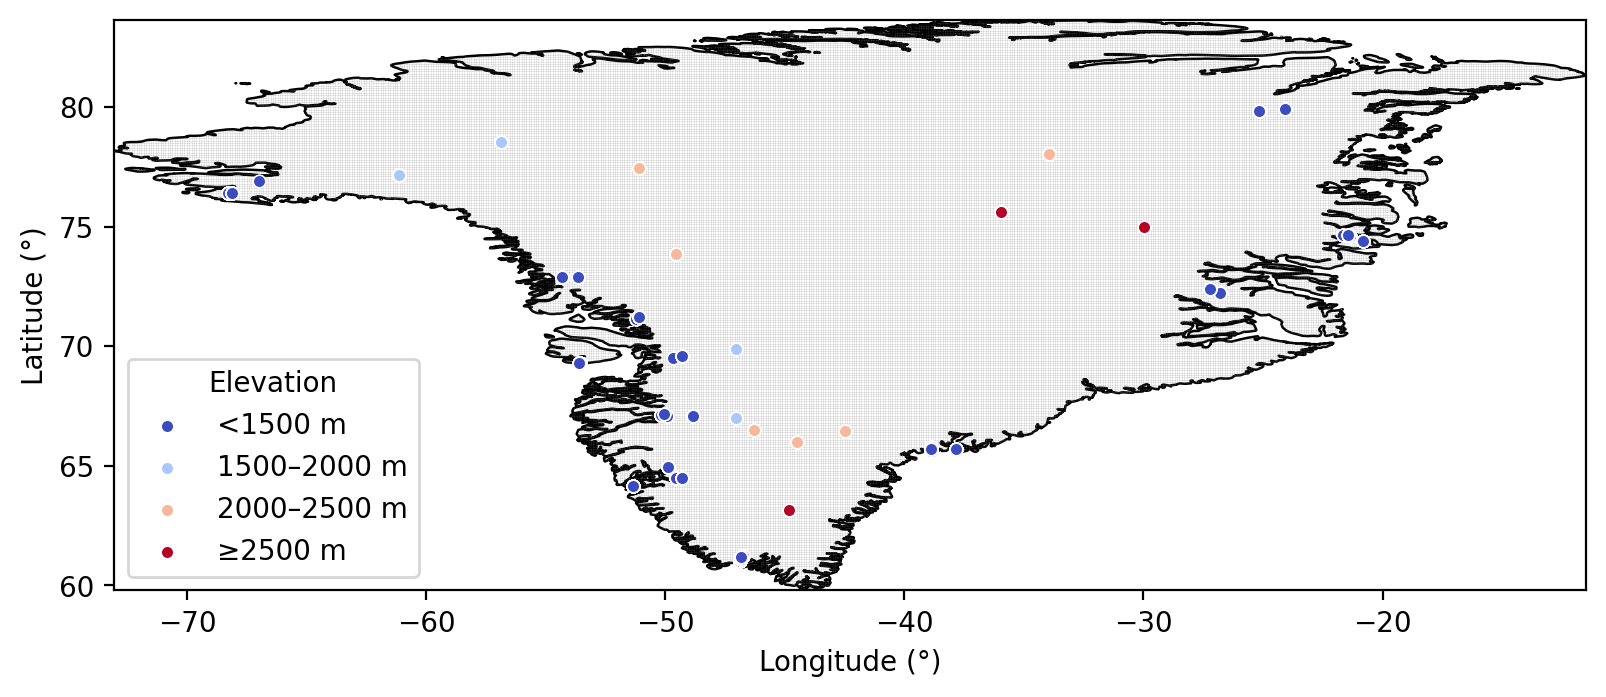

In [3]:
# -*- coding: utf-8 -*-
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from shapely.geometry import LineString
import warnings
from matplotlib.cm import get_cmap

BOUNDARY_SHP = r"C:\greenland\Greenland_shp\Gboundry.shp"
STATION_CSV  = r"C:\Users\greenlandProject\ERA5LAND\merged_allfeature.csv"

LAT_COL = "latitude"
LON_COL = "longitude"
ELEV_CANDIDATES = ["altitude_last_valid","elevation","altitude","alt","h","z","Elev","ELEV"]

GRID_STEP = 0.1     # 0.1°
GRID_LW   = 0.25
GRID_ALPHA= 0.25
GRID_COLOR= "grey"

POINT_SIZE = 20
POINT_EDGE = "white"
POINT_EW   = 0.5

BIN_EDGES   = [-1e9,1500,2000,2500,3000]
BIN_LABELS  = ["<1500 m","1500–2000 m","2000–2500 m","≥2500 m"]
cmap = get_cmap("coolwarm", 4)
BIN_COLORS = [cmap(i) for i in range(4)]

# 1) 边界 → WGS84
boundary = gpd.read_file(BOUNDARY_SHP)
if boundary.crs is None:
    warnings.warn("边界SHP未带CRS，默认EPSG:4326。")
    boundary = boundary.set_crs(epsg=4326)
elif boundary.crs.to_epsg() != 4326:
    boundary = boundary.to_crs(epsg=4326)

# 2) 生成0.1°经纬线并裁剪到边界内（只保留线段）
minx, miny, maxx, maxy = boundary.total_bounds
align_floor = lambda x,s: np.floor(x/s)*s
align_ceil  = lambda x,s: np.ceil(x/s)*s
gx_min = align_floor(minx, GRID_STEP); gx_max = align_ceil(maxx, GRID_STEP)
gy_min = align_floor(miny, GRID_STEP); gy_max = align_ceil(maxy, GRID_STEP)

lon_vals = np.arange(gx_min, gx_max + 1e-9, GRID_STEP)
lat_vals = np.arange(gy_min, gy_max + 1e-9, GRID_STEP)

# 原始线
lon_geoms = [LineString([(lon, gy_min), (lon, gy_max)]) for lon in lon_vals]
lat_geoms = [LineString([(gx_min, lat), (gx_max, lat)]) for lat in lat_vals]
gdf_lon = gpd.GeoDataFrame(geometry=lon_geoms, crs="EPSG:4326")
gdf_lat = gpd.GeoDataFrame(geometry=lat_geoms, crs="EPSG:4326")

# 只保留边界内的线段
grid_lon_in = gpd.clip(gdf_lon, boundary)
grid_lat_in = gpd.clip(gdf_lat, boundary)

# 3) 站点
df = pd.read_csv(STATION_CSV)
for col in [LAT_COL, LON_COL]:
    if col not in df.columns:
        raise ValueError(f"CSV缺少列：{col}")
elev_col = next((c for c in ELEV_CANDIDATES if c in df.columns), None)
if elev_col is None:
    warnings.warn("未找到海拔列，默认归入<1500 m档。")
    df["_tmp_elev_"] = -1e6
    elev_col = "_tmp_elev_"

gdf_pts = gpd.GeoDataFrame(df.copy(),
                           geometry=gpd.points_from_xy(df[LON_COL], df[LAT_COL]),
                           crs="EPSG:4326")
gdf_pts = gpd.sjoin(gdf_pts, boundary[["geometry"]], predicate="within", how="inner")
gdf_pts.drop(columns=[c for c in gdf_pts.columns if c.startswith("index_")], inplace=True, errors="ignore")

elev = np.minimum(gdf_pts[elev_col].astype(float).to_numpy(), 3000)
gdf_pts["_bin"] = pd.cut(elev, bins=BIN_EDGES, labels=BIN_LABELS, include_lowest=True).astype(str)

# 4) 画图（底图无填充，只描边；网格是线，不是面）
fig, ax = plt.subplots(figsize=(9.5, 9), dpi=200)
ax.set_facecolor("white")

# 边界线（无填充）
boundary.plot(ax=ax, facecolor="none", edgecolor="black", linewidth=0.9, zorder=1)

# 网格线（已裁剪，仅内部线段）
grid_lon_in.plot(ax=ax, color=GRID_COLOR, linewidth=GRID_LW, alpha=GRID_ALPHA, zorder=2)
grid_lat_in.plot(ax=ax, color=GRID_COLOR, linewidth=GRID_LW, alpha=GRID_ALPHA, zorder=2)

# 站点
for label, color in zip(BIN_LABELS, BIN_COLORS):
    sub = gdf_pts[gdf_pts["_bin"] == label]
    if len(sub):
        sub.plot(ax=ax, markersize=POINT_SIZE, marker="o",
                 facecolor=color, edgecolor=POINT_EDGE, linewidth=POINT_EW,
                 label=label, zorder=3)

# 轴与图例
minx, miny, maxx, maxy = boundary.total_bounds
ax.set_xlim(minx, maxx); ax.set_ylim(miny, maxy)
ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("Longitude (°)"); ax.set_ylabel("Latitude (°)")
leg = ax.legend(title="Elevation", loc="lower left", frameon=True)
for h in leg.legendHandles: h.set_alpha(1.0)
plt.tight_layout(); plt.show()


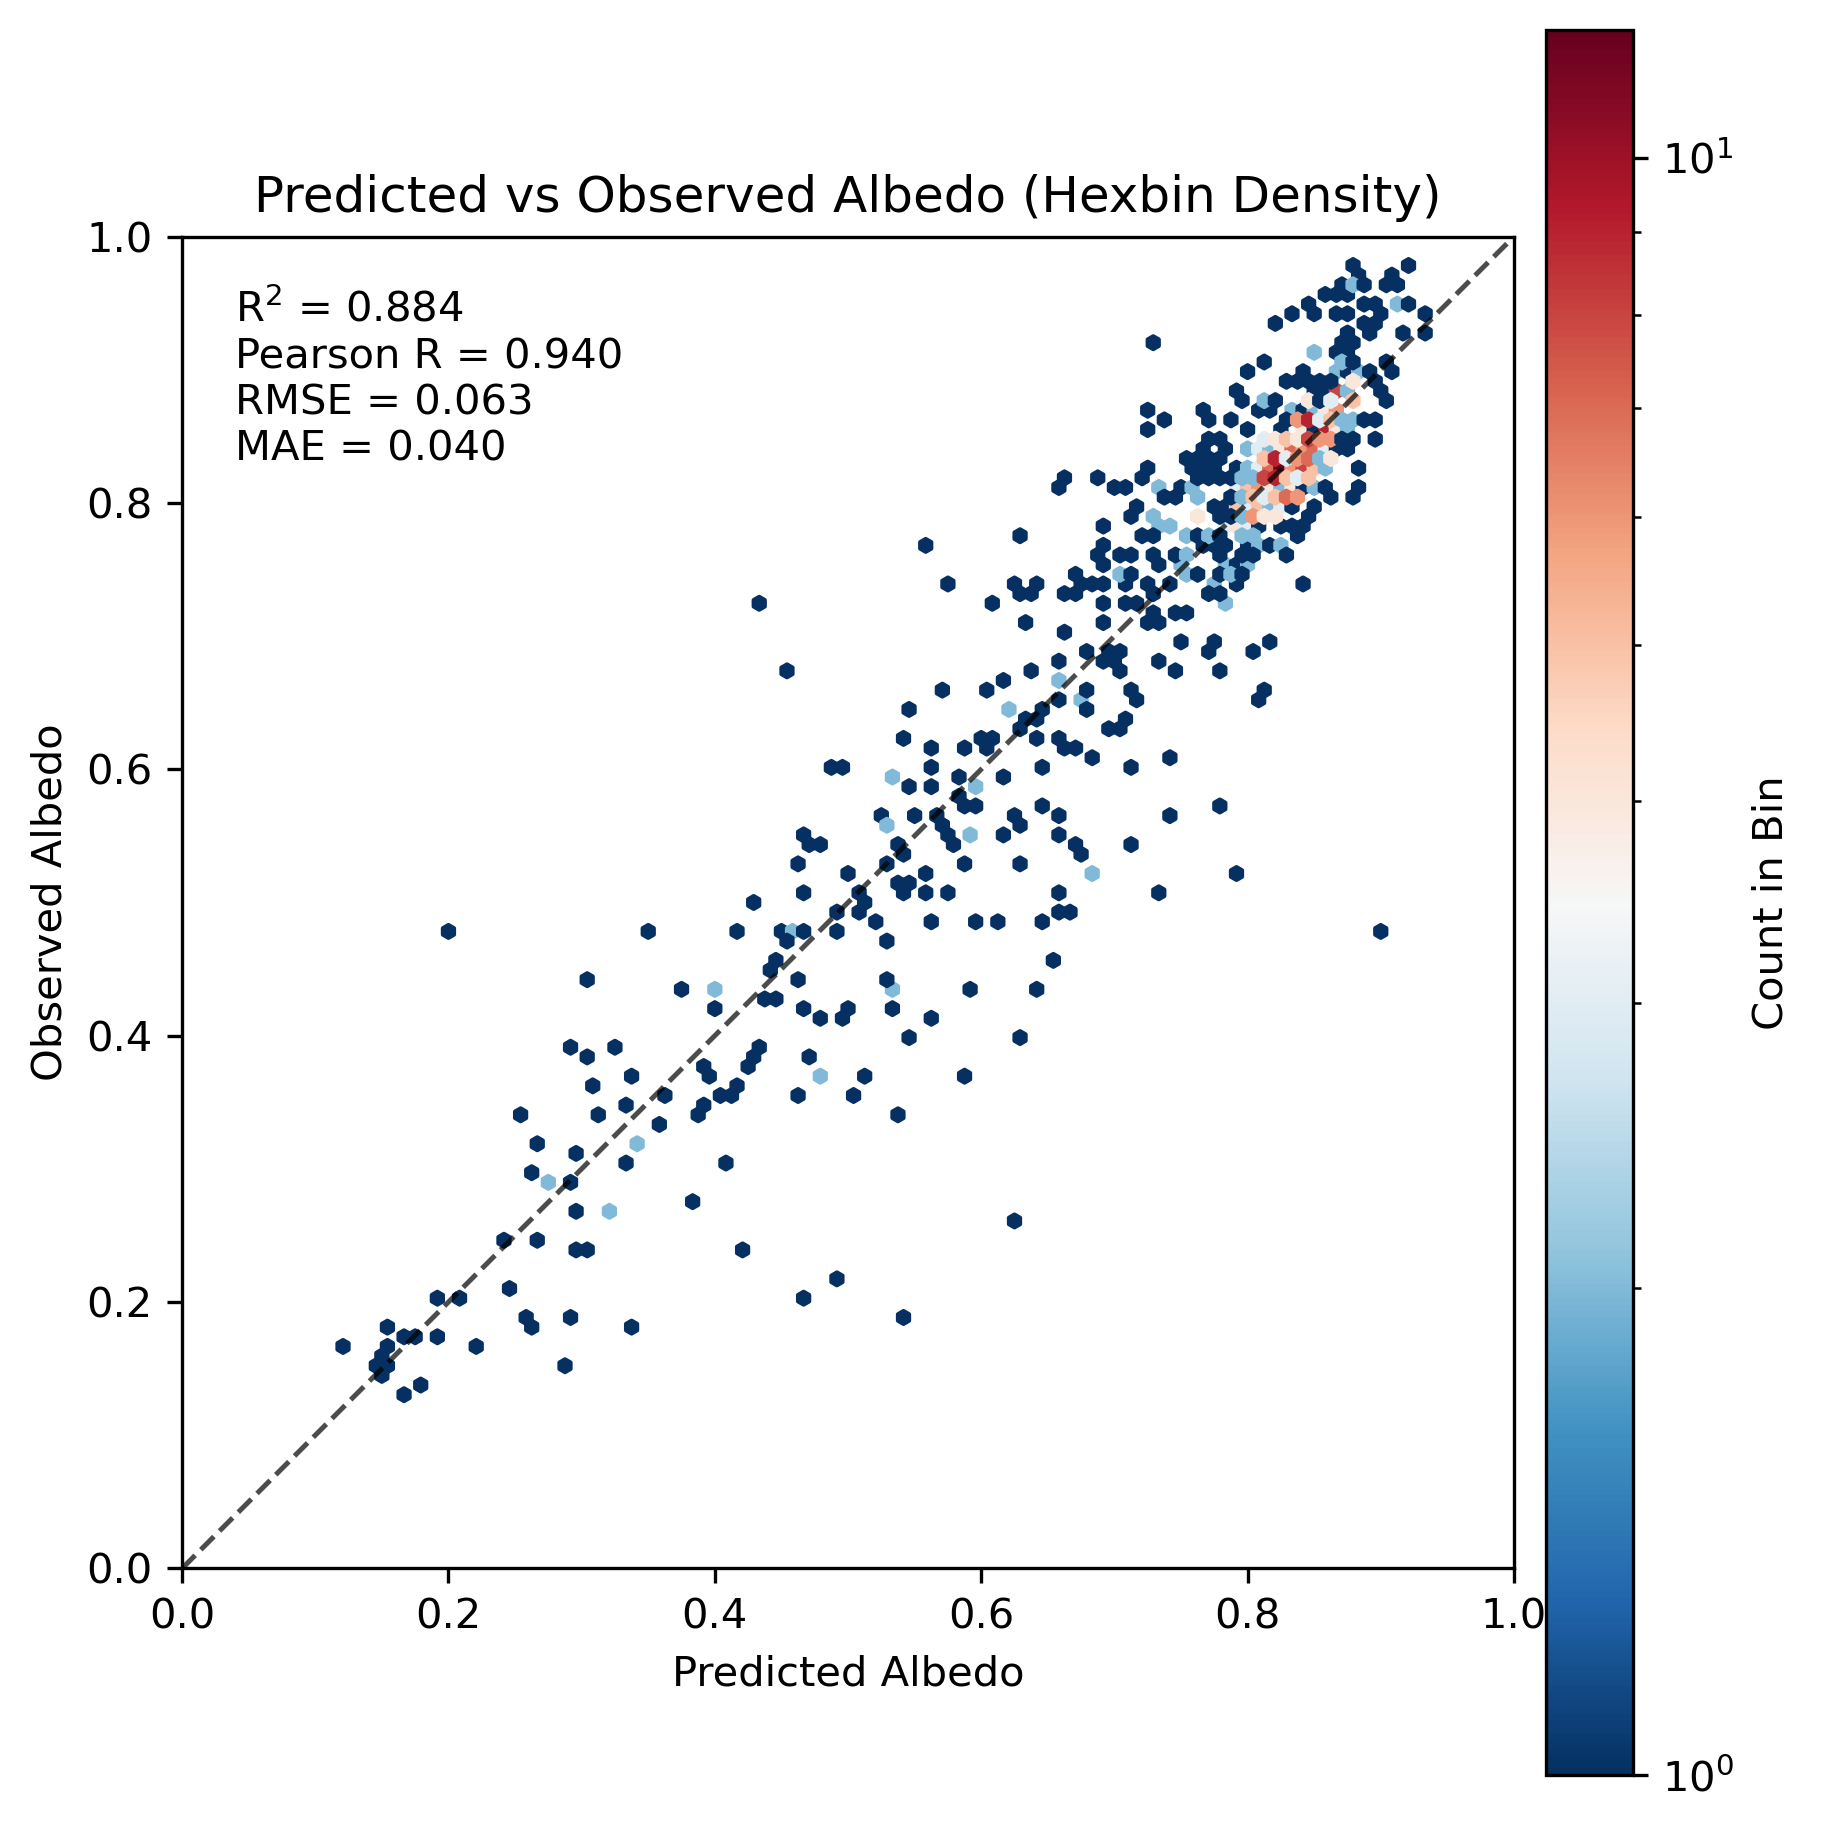

In [1]:
# -*- coding: utf-8 -*-
# 用 stack_test_predictions_917.csv 重画密度散点（hexbin），
# ①角标统计量含 R2 / Pearson_R / RMSE / MAE
# ②提高“黏在回归线”的密集感（更高 gridsize、等比例坐标、对数计数）
# ③坐标轴严格限定在 [0, 1]

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from scipy.stats import pearsonr

# ===== 读取数据 =====
csv_path = "stack_test_predictions_917.csv"
df = pd.read_csv(csv_path)
y_true = df["true_albedo"].values
y_pred = df["pred_albedo"].values

# ===== 指标 =====
R2    = r2_score(y_true, y_pred)
Pear  = pearsonr(y_true, y_pred)[0]
RMSE  = np.sqrt(mean_squared_error(y_true, y_pred))
MAE   = mean_absolute_error(y_true, y_pred)

# ===== 画图（hexbin 密度散点）=====
plt.figure(figsize=(6.2, 6.2), dpi=300)

# 提高“密集感”：更细网格 + log 计数 + 等比例坐标
GRIDSIZE = 120  # 可调：80~160
hb = plt.hexbin(
    y_pred, y_true,              # 横轴=Predicted，纵轴=Observed（和示例一致）
    gridsize=GRIDSIZE,
    bins="log",                  # 对数计数：突出高密区域（在1:1线附近形成“红脊”）
    cmap="RdBu_r",               # 低计数蓝，高计数红
    mincnt=1,
    extent=(0, 1, 0, 1)          # 明确限定到 [0,1]×[0,1]
)

# 1:1 参考线
plt.plot([0, 1], [0, 1], ls="--", lw=1.2, color="k", alpha=0.7)

# 坐标轴与比例
plt.xlim(0, 1); plt.ylim(0, 1)
plt.gca().set_aspect("equal", adjustable="box")  # 等比例，视觉上更贴近对角线
plt.xlabel("Predicted Albedo")
plt.ylabel("Observed Albedo")
plt.title("Predicted vs Observed Albedo (Hexbin Density)")

# 角标统计量
txt = (f"R$^2$ = {R2:.3f}\n"
       f"Pearson R = {Pear:.3f}\n"
       f"RMSE = {RMSE:.3f}\n"
       f"MAE = {MAE:.3f}")
plt.text(0.04, 0.96, txt, ha="left", va="top",
         transform=plt.gca().transAxes, fontsize=10)

# 颜色条：计数
cbar = plt.colorbar(hb, pad=0.02)
cbar.set_label("Count in Bin")

plt.tight_layout()
plt.savefig("scatter_hexbin_albedo_dense.png")
plt.show()


In [3]:
import cdsapi
print("🔍 正在测试 Copernicus CDS 连接...")
c = cdsapi.Client()
print("✅ 成功连接 CDS API！")


🔍 正在测试 Copernicus CDS 连接...
✅ 成功连接 CDS API！


In [7]:
# -*- coding: utf-8 -*-
"""
Re-download ERA5-Land hourly SSRD & STRD for Greenland (updated extent)
Period: 2022-09 → 2024-02
Region: lon −75 ~ −10, lat 59 ~ 85
Dataset: reanalysis-era5-land
"""

import cdsapi
import os
import calendar
import time

# === 1. 输出路径 ===
out_dir = r"C:\Users\11823\ERA5LAND\Hourly_SSRD_STRD"
os.makedirs(out_dir, exist_ok=True)

# === 2. 年月范围 ===
years_months = [
    ("2022", ["09", "10", "11", "12"]),
    ("2023", [f"{i:02d}" for i in range(1, 13)]),
    ("2024", ["01", "02"]),
]

# === 3. 初始化客户端 ===
c = cdsapi.Client()

# === 4. 下载循环 ===
for year, months in years_months:
    for month in months:
        ndays = calendar.monthrange(int(year), int(month))[1]
        days = [f"{d:02d}" for d in range(1, ndays + 1)]
        out_file = os.path.join(out_dir, f"ERA5LAND_Hourly_SSRD_STRD_{year}{month}.nc")

        # 强制重新下载：若存在则删除
        if os.path.exists(out_file):
            print(f"⚠️ 删除旧文件并重新下载: {out_file}")
            try:
                os.remove(out_file)
            except Exception as e:
                print(f"❌ 无法删除旧文件: {e}")
                continue

        print(f"\n⬇️ 正在下载 {year}-{month} (Greenland updated area)...")

        # === 下载并自动重试 ===
        for attempt in range(2):
            try:
                c.retrieve(
                    "reanalysis-era5-land",
                    {
                        "variable": [
                            "surface_solar_radiation_downwards",
                            "surface_thermal_radiation_downwards",
                        ],
                        "year": year,
                        "month": month,
                        "day": days,
                        "time": [f"{h:02d}:00" for h in range(24)],
                        "area": [85, -75, 59, -10],  # 北, 西, 南, 东
                        "format": "netcdf",
                    },
                    out_file,
                )
                print(f"✅ 下载完成: {out_file}")
                break  # 成功则退出重试循环

            except Exception as e:
                print(f"⚠️ 下载失败 (第 {attempt+1} 次): {e}")
                if attempt == 0:
                    print("⏳ 等待 20 秒后重试 ...")
                    time.sleep(20)
                else:
                    print("❌ 两次尝试都失败，跳过该月。")

print("\n🎯 所有月份重新下载任务完成！")


⚠️ 删除旧文件并重新下载: C:\Users\11823\ERA5LAND\Hourly_SSRD_STRD\ERA5LAND_Hourly_SSRD_STRD_202209.nc

⬇️ 正在下载 2022-09 (Greenland updated area)...


2025-10-26 19:58:25,474 INFO Request ID is b5015b63-1a6e-4351-86c2-9ab791559292
2025-10-26 19:58:25,544 INFO status has been updated to accepted
2025-10-26 20:00:19,635 INFO status has been updated to running
2025-10-26 20:04:44,519 INFO status has been updated to successful


f2037d0aa8153f42c31df936d58e3cbe.zip:   0%|          | 0.00/230M [00:00<?, ?B/s]

2025-10-26 20:05:08,858 INFO Request ID is 89174d98-72d2-4bae-8519-84e3f7a85ce8


✅ 下载完成: C:\Users\11823\ERA5LAND\Hourly_SSRD_STRD\ERA5LAND_Hourly_SSRD_STRD_202209.nc

⬇️ 正在下载 2022-10 (Greenland updated area)...


...

2025-10-26 21:17:11,443 INFO Request ID is a6090197-0db3-4290-a879-8fc41782a678


✅ 下载完成: C:\Users\11823\ERA5LAND\Hourly_SSRD_STRD\ERA5LAND_Hourly_SSRD_STRD_202401.nc

⬇️ 正在下载 2024-02 (Greenland updated area)...


2025-10-26 21:17:11,512 INFO status has been updated to accepted
2025-10-26 21:17:25,373 INFO status has been updated to running
2025-10-26 21:21:30,417 INFO status has been updated to successful


3af889f39d89cd9edf2fc03fdb55070c.zip:   0%|          | 0.00/173M [00:00<?, ?B/s]

✅ 下载完成: C:\Users\11823\ERA5LAND\Hourly_SSRD_STRD\ERA5LAND_Hourly_SSRD_STRD_202402.nc

🎯 所有月份重新下载任务完成！


In [4]:
# -*- coding: utf-8 -*-
"""
Combine ERA5-Land monthly NetCDFs using valid_time instead of time
"""

import xarray as xr
import numpy as np
import os, glob

root = r"C:\Users\11823\era5land\Hourly_SSRD_STRD\unzipped_fixed"
out_path = os.path.join(root, "SSRD_STRD_202209202402.nc")

folders = sorted(glob.glob(os.path.join(root, "ERA5LAND_Hourly_SSRD_STRD_*")))
print(f"🧾 共检测到 {len(folders)} 个月份。")

monthly_datasets = []

for folder in folders:
    month_name = os.path.basename(folder)
    nc_path = os.path.join(folder, "data_0.nc")
    if not os.path.exists(nc_path):
        print(f"⚠️ 缺少 {nc_path} ，跳过。")
        continue

    print(f"⏳ 读取 {month_name} ...")
    ds = xr.open_dataset(nc_path, engine="netcdf4")

    # === 改关键维度 ===
    if "valid_time" in ds:
        ds = ds.rename({"valid_time": "time"})

    # === 确保时间格式正确 ===
    if not np.issubdtype(ds.time.dtype, np.datetime64):
        ds["time"] = xr.decode_cf(ds).time

    # Hourly → Daily
    ds_daily = ds.resample(time="1D").mean()

    # Daily → Monthly
    ds_month = ds_daily.resample(time="1MS").mean()

    # 给时间坐标设定为该月中旬
    month_str = month_name[-6:]  # e.g. 202209
    ds_month = ds_month.assign_coords(
        time=[np.datetime64(f"{month_str[:4]}-{month_str[4:]}-15")]
    )

    monthly_datasets.append(ds_month)
    ds.close()

print("📦 所有月度平均已计算，开始合并 ...")

combined = xr.concat(monthly_datasets, dim="time")
combined = combined.sortby("time")

combined.attrs.update({
    "title": "ERA5-Land Monthly Mean SSRD & STRD (Greenland, 2022-09 to 2024-02)",
    "source": "ECMWF Copernicus Climate Data Store (reanalysis-era5-land)",
    "processing": "valid_time → daily mean → monthly mean",
    "spatial_extent": "lon −75 to −10, lat 59 to 85",
    "created_by": "汝清 朱 (TU Berlin)"
})

print("💾 正在写出 NetCDF ...")
combined.to_netcdf(out_path, engine="netcdf4")
print(f"✅ 合并完成: {out_path}")


🧾 共检测到 18 个月份。
⏳ 读取 ERA5LAND_Hourly_SSRD_STRD_202209 ...
⏳ 读取 ERA5LAND_Hourly_SSRD_STRD_202210 ...
⏳ 读取 ERA5LAND_Hourly_SSRD_STRD_202211 ...
⏳ 读取 ERA5LAND_Hourly_SSRD_STRD_202212 ...
⏳ 读取 ERA5LAND_Hourly_SSRD_STRD_202301 ...
⏳ 读取 ERA5LAND_Hourly_SSRD_STRD_202302 ...
⏳ 读取 ERA5LAND_Hourly_SSRD_STRD_202303 ...
⏳ 读取 ERA5LAND_Hourly_SSRD_STRD_202304 ...
⏳ 读取 ERA5LAND_Hourly_SSRD_STRD_202305 ...
⏳ 读取 ERA5LAND_Hourly_SSRD_STRD_202306 ...
⏳ 读取 ERA5LAND_Hourly_SSRD_STRD_202307 ...
⏳ 读取 ERA5LAND_Hourly_SSRD_STRD_202308 ...
⏳ 读取 ERA5LAND_Hourly_SSRD_STRD_202309 ...
⏳ 读取 ERA5LAND_Hourly_SSRD_STRD_202310 ...
⏳ 读取 ERA5LAND_Hourly_SSRD_STRD_202311 ...
⏳ 读取 ERA5LAND_Hourly_SSRD_STRD_202312 ...
⏳ 读取 ERA5LAND_Hourly_SSRD_STRD_202401 ...
⏳ 读取 ERA5LAND_Hourly_SSRD_STRD_202402 ...
📦 所有月度平均已计算，开始合并 ...
💾 正在写出 NetCDF ...
✅ 合并完成: C:\Users\11823\era5land\Hourly_SSRD_STRD\unzipped_fixed\SSRD_STRD_202209202402.nc


In [2]:
# -*- coding: utf-8 -*-
"""
Extract first timestamp (e.g. 1st day 00:00) from each ERA5-Land monthly file
and merge into one NetCDF.
"""

import xarray as xr
import numpy as np
import os, glob

# === 输入输出路径 ===
root = r"C:\Users\11823\era5land\Hourly_SSRD_STRD\unzipped_fixed"
out_path = os.path.join(root, "SSRD_STRD_firsthour_202209202402.nc")

# === 获取所有月份文件夹 ===
folders = sorted(glob.glob(os.path.join(root, "ERA5LAND_Hourly_SSRD_STRD_*")))
print(f"🧾 检测到 {len(folders)} 个月份。")

snapshots = []

for folder in folders:
    month_name = os.path.basename(folder)
    nc_path = os.path.join(folder, "data_0.nc")
    if not os.path.exists(nc_path):
        print(f"⚠️ 缺少 {nc_path}，跳过。")
        continue

    print(f"⏳ 读取 {month_name} ...")
    ds = xr.open_dataset(nc_path, engine="netcdf4")

    # === 时间维修正 ===
    if "valid_time" in ds:
        ds = ds.rename({"valid_time": "time"})

    # === 取第一个时间点（当月1日00:00） ===
    first_time = ds.time.values[0]
    ds_sel = ds.isel(time=0)

    # 统一为该月中旬的标签，方便后续作图
    month_str = month_name[-6:]
    ds_sel = ds_sel.expand_dims(
        time=[np.datetime64(f"{month_str[:4]}-{month_str[4:]}-15")]
    )

    snapshots.append(ds_sel)
    ds.close()

# === 合并所有月份 ===
print("📦 合并所有月份快照 ...")
combined = xr.concat(snapshots, dim="time")
combined = combined.sortby("time")

# === 添加元数据 ===
combined.attrs.update({
    "title": "ERA5-Land Monthly Snapshots (1st day 00:00 UTC, Greenland)",
    "source": "ECMWF Copernicus Climate Data Store (reanalysis-era5-land)",
    "processing": "Extracted first hourly record per month (1st day 00:00 UTC)",
    "spatial_extent": "lon −75 to −10, lat 59 to 85",
    "created_by": "汝清 朱 (TU Berlin)"
})

# === 保存 ===
print("💾 正在保存 NetCDF ...")
combined.to_netcdf(out_path, engine="netcdf4")
print(f"✅ 完成: {out_path}")


🧾 检测到 18 个月份。
⏳ 读取 ERA5LAND_Hourly_SSRD_STRD_202209 ...
⏳ 读取 ERA5LAND_Hourly_SSRD_STRD_202210 ...
⏳ 读取 ERA5LAND_Hourly_SSRD_STRD_202211 ...
⏳ 读取 ERA5LAND_Hourly_SSRD_STRD_202212 ...
⏳ 读取 ERA5LAND_Hourly_SSRD_STRD_202301 ...
⏳ 读取 ERA5LAND_Hourly_SSRD_STRD_202302 ...
⏳ 读取 ERA5LAND_Hourly_SSRD_STRD_202303 ...
⏳ 读取 ERA5LAND_Hourly_SSRD_STRD_202304 ...
⏳ 读取 ERA5LAND_Hourly_SSRD_STRD_202305 ...
⏳ 读取 ERA5LAND_Hourly_SSRD_STRD_202306 ...
⏳ 读取 ERA5LAND_Hourly_SSRD_STRD_202307 ...
⏳ 读取 ERA5LAND_Hourly_SSRD_STRD_202308 ...
⏳ 读取 ERA5LAND_Hourly_SSRD_STRD_202309 ...
⏳ 读取 ERA5LAND_Hourly_SSRD_STRD_202310 ...
⏳ 读取 ERA5LAND_Hourly_SSRD_STRD_202311 ...
⏳ 读取 ERA5LAND_Hourly_SSRD_STRD_202312 ...
⏳ 读取 ERA5LAND_Hourly_SSRD_STRD_202401 ...
⏳ 读取 ERA5LAND_Hourly_SSRD_STRD_202402 ...
📦 合并所有月份快照 ...
💾 正在保存 NetCDF ...
✅ 完成: C:\Users\11823\era5land\Hourly_SSRD_STRD\unzipped_fixed\SSRD_STRD_firsthour_202209202402.nc


In [7]:
# -*- coding: utf-8 -*-
"""
计算 ERA5-Land 文件中 SSRD 与 STRD 在 2021–2022 年的每月平均值
"""

import xarray as xr
import pandas as pd

# === 文件路径 ===
path = r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\ERA5LANDfeature_greenland.nc"

# === 打开数据集 ===
ds = xr.open_dataset(path)

# 自动识别时间维度名（valid_time 或 time）
time_name = "valid_time" if "valid_time" in ds.dims else "time"
ds = ds.rename({time_name: "time"})

# 只保留需要的两个变量
vars_to_use = [v for v in ["ssrd", "strd"] if v in ds.data_vars]
ds = ds[vars_to_use]

# 只筛选 2021–2022 年
ds_sel = ds.sel(time=slice("2021-01-01", "2022-12-31"))

# === 按月份计算空间均值（经纬度平均）并输出 ===
# 若无需空间平均，可删除 mean(dim=[...])
monthly_mean = (
    ds_sel
    .mean(dim=["latitude", "longitude"])  # 空间平均
    .groupby("time.month")
    .mean()
)

# === 打印结果 ===
print("========== 2021–2022 每月平均辐射 (单位与原文件一致) ==========")
for var in vars_to_use:
    print(f"\n📘 {var.upper()} 每月平均：")
    df = pd.DataFrame({
        "Month": range(1, 13),
        "MeanValue": monthly_mean[var].values.round(2)
    })
    print(df.to_string(index=False))


========== 2021–2022 每月平均辐射 (单位与原文件一致) ==========

📘 SSRD 每月平均：
 Month   MeanValue
     1    87065.70
     2   843049.25
     3  5256686.00
     4 14828885.00
     5 26093308.00
     6 29949908.00
     7 25581676.00
     8 16739866.00
     9  5134320.50
    10  1249487.75
    11   122594.39
    12    18967.38

📘 STRD 每月平均：
 Month  MeanValue
     1 13722900.0
     2 13086260.0
     3 13588050.0
     4 15155568.0
     5 16217630.0
     6 18910636.0
     7 21184710.0
     8 20692844.0
     9 13957335.0
    10 12327768.0
    11 11035821.0
    12 10786283.0


In [18]:
# -*- coding: utf-8 -*-
"""
ERA5-Land Hourly -> Monthly mean flux (W/m²) -> J/m²/day
Period: 2022-09 ~ 2024-02
Inputs: <root>\ERA5LAND_Hourly_SSRD_STRD_YYYYMM\data_0.nc
Output:
  1) 打印月表（空间平均，单位 J/m²/day）
  2) CSV: monthly_ssrd_strd_JperDay_202209_202402.csv
  3) NetCDF: monthly_ssrd_strd_JperDay_202209_202402.nc  (可选，包含整域栅格)
"""

import os, glob
import numpy as np
import pandas as pd
import xarray as xr

# === 你的目录（已按你之前的结构）===
root = r"C:\Users\11823\era5land\Hourly_SSRD_STRD\unzipped_fixed"

# === 月份列表 ===
months = []
for y, mlist in [("2022", ["09","10","11","12"]),
                 ("2023", [f"{i:02d}" for i in range(1,13)]),
                 ("2024", ["01","02"])]:
    for m in mlist:
        months.append(f"{y}{m}")

# === 工具函数：把积算量 -> 每小时增量（修复起报归零）===
def hourly_increment(acc):
    """
    acc: (time, lat, lon) 的积算量 (J/m²)
    return: 每小时能量增量 (J/m²/小时)
    规则：
      inc = diff(acc, 1h); 若 diff<0（起报重置），则 inc := acc（当前小时值）
      第一个小时 inc := acc[0]
    """
    diff = acc - acc.shift(time=1)
    inc = xr.where(diff >= 0, diff, acc)
    inc = inc.assign_coords(time=acc.time)
    # 首小时（没有前值），取自身：
    inc[{ "time": 0 }] = acc.isel(time=0)
    return inc

# === 存放结果（空间平均）===
rows = []

# === 可选：为整域输出准备列表（每月一张栅格）===
rasters_ssrd = []
rasters_strd = []
time_coords = []

for ym in months:
    folder = os.path.join(root, f"ERA5LAND_Hourly_SSRD_STRD_{ym}")
    path = os.path.join(folder, "data_0.nc")
    if not os.path.exists(path):
        print(f"⚠️ 缺文件，跳过：{path}")
        continue

    print(f"⏳ 处理 {ym} ...")
    ds = xr.open_dataset(path, engine="netcdf4")

    # 统一时间维名称
    if "valid_time" in ds.variables:
        ds = ds.rename({"valid_time":"time"})
    ds = ds.sortby("time")

    # 取变量（有的文件叫长名/短名，这里兼容）
    def pick(ds, candidates):
        for k in candidates:
            if k in ds.variables:
                return ds[k]
        raise KeyError(f"找不到变量：{candidates}")

    ssrd = pick(ds, ["ssrd","surface_solar_radiation_downwards"])
    strd = pick(ds, ["strd","surface_thermal_radiation_downwards"])

    # —— 积算量 -> 每小时增量 (J/m²/小时)
    ssrd_inc = hourly_increment(ssrd)
    strd_inc = hourly_increment(strd)

    # —— 每小时功率 (W/m²) = 每小时增量 / 3600
    ssrd_flux = ssrd_inc / 3600.0
    strd_flux = strd_inc / 3600.0

    # —— 月平均功率（对“小时”做算术平均）
    ssrd_mean_W = ssrd_flux.mean(dim="time")
    strd_mean_W = strd_flux.mean(dim="time")

    # —— 转成 J/m²/day（你要的最终口径）
    ssrd_JperDay = ssrd_mean_W * 86400.0
    strd_JperDay = strd_mean_W * 86400.0

    # —— 空间平均（未加权；需要加权可改成权重 cos(phi)）
    ssrd_space_mean = float(ssrd_JperDay.mean().values)
    strd_space_mean = float(strd_JperDay.mean().values)

    rows.append({
        "YYYYMM": ym,
        "SSRD_J_per_day_mean": ssrd_space_mean,
        "STRD_J_per_day_mean": strd_space_mean
    })

    # —— 可选：保存整域栅格到列表（用于输出 NetCDF）
    # 给当前月放一个“该月中旬”时间标签
    t_mid = np.datetime64(f"{ym[:4]}-{ym[4:]}-15")
    time_coords.append(t_mid)
    rasters_ssrd.append(ssrd_JperDay.expand_dims(time=[t_mid]))
    rasters_strd.append(strd_JperDay.expand_dims(time=[t_mid]))

    ds.close()

# === 打印表格（空间平均）
df = pd.DataFrame(rows).sort_values("YYYYMM").reset_index(drop=True)
print("\n📊 每月（空间平均）SSRD/STRD：J/m²/day")
print(df.to_string(index=False))

# === 保存 CSV
csv_path = os.path.join(root, "monthly_ssrd_strd_JperDay_202209_202402.csv")
df.to_csv(csv_path, index=False, float_format="%.3f")
print(f"\n✅ CSV 已保存：{csv_path}")

# ===（可选）输出 NetCDF：整域“月值”(J/m²/day)，time 维长度=18
if len(rasters_ssrd) > 0:
    ds_out = xr.Dataset({
        "ssrd_J_per_day": xr.concat(rasters_ssrd, dim="time"),
        "strd_J_per_day": xr.concat(rasters_strd, dim="time"),
    })
    ds_out = ds_out.sortby("time")

    # 元数据
    ds_out["ssrd_J_per_day"].attrs.update({
        "units": "J m-2 day-1",
        "long_name": "Surface solar radiation downwards (monthly mean flux × 86400)",
        "note": "Computed from hourly accumulated flux: diff->/3600->time mean->×86400"
    })
    ds_out["strd_J_per_day"].attrs.update({
        "units": "J m-2 day-1",
        "long_name": "Surface thermal radiation downwards (monthly mean flux × 86400)",
        "note": "Computed from hourly accumulated flux: diff->/3600->time mean->×86400"
    })
    ds_out.attrs.update({
        "title": "ERA5-Land SSRD/STRD monthly J/m^2/day (official time-mean flux × 86400)",
        "period": "2022-09 to 2024-02",
        "method": "hourly accumulated -> hourly increments -> /3600 -> monthly time mean -> ×86400",
    })

    nc_out = os.path.join(root, "monthly_ssrd_strd_JperDay_202209_202402.nc")
    ds_out.to_netcdf(nc_out, engine="netcdf4")
    print(f"✅ NetCDF 已保存（整域月值，J/m²/day）：{nc_out}")

# === 如需纬度加权平均（可选）===
# lat = ds_out.latitude
# w = np.cos(np.deg2rad(lat))
# w = w / w.mean()  # 归一
# weighted_mean = (ds_out["ssrd_J_per_day"] * w).mean(dim=["latitude","longitude"])


⏳ 处理 202209 ...
⏳ 处理 202210 ...
⏳ 处理 202211 ...
⏳ 处理 202212 ...
⏳ 处理 202301 ...
⏳ 处理 202302 ...
⏳ 处理 202303 ...
⏳ 处理 202304 ...
⏳ 处理 202305 ...
⏳ 处理 202306 ...
⏳ 处理 202307 ...
⏳ 处理 202308 ...
⏳ 处理 202309 ...
⏳ 处理 202310 ...
⏳ 处理 202311 ...
⏳ 处理 202312 ...
⏳ 处理 202401 ...
⏳ 处理 202402 ...

📊 每月（空间平均）SSRD/STRD：J/m²/day
YYYYMM  SSRD_J_per_day_mean  STRD_J_per_day_mean
202209         7.249559e+06           22000920.0
202210         2.348598e+06           18058402.0
202211         3.304696e+05           16198024.0
202212         5.700713e+04           14792823.0
202301         1.692976e+05           13432557.0
202302         1.183567e+06           14132591.0
202303         6.633904e+06           14382102.0
202304         1.533066e+07           15942587.0
202305         2.520548e+07           17734428.0
202306         2.908396e+07           20878262.0
202307         2.495843e+07           23395240.0
202308         1.646556e+07           22868784.0
202309         9.038803e+06           1975710

In [2]:
# -*- coding: utf-8 -*-
"""
暴力修复版：坐标完全一样，直接复制数组，不插值！
"""
import xarray as xr
import numpy as np
import pandas as pd

target_path = r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\ERA5LANDfeature_greenland_updated.nc"
new_path    = r"C:\Users\11823\era5land\Hourly_SSRD_STRD\unzipped_fixed\Grennlandmonthly_ssrd_strd_202209.nc"
save_path   = r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\ERA5LANDfeature_greenland_fixed_202209_FINAL.nc"

print("="*70)
print("🔧 暴力修复：直接复制数组")
print("="*70)

# ===== 1. 加载 =====
print("\n1️⃣ 加载文件...")
ds_target = xr.open_dataset(target_path).load()
ds_new = xr.open_dataset(new_path).load()

# ===== 2. 标准化 =====
def standardize_dims(ds):
    for old in ["valid_time", "time"]:
        if old in ds.dims or old in ds.coords:
            ds = ds.rename({old: "time"})
            break
    for old in ["lat", "latitude"]:
        if old in ds.coords:
            ds = ds.rename({old: "latitude"})
            break
    for old in ["lon", "longitude"]:
        if old in ds.coords:
            ds = ds.rename({old: "longitude"})
            break
    return ds

ds_target = standardize_dims(ds_target)
ds_new = standardize_dims(ds_new)

# ===== 3. 找变量和索引 =====
print("2️⃣ 查找索引...")
v_ssrd = [v for v in ds_new.data_vars if "ssrd" in v.lower()][0]
v_strd = [v for v in ds_new.data_vars if "strd" in v.lower()][0]

time_new = pd.to_datetime(ds_new.time.values)
idx_new = [i for i, t in enumerate(time_new) if t.year == 2022 and t.month == 9][0]
print(f"   新文件 2022-09 索引: {idx_new}")

time_target = pd.to_datetime(ds_target.time.values)
idx_target_list = [i for i, t in enumerate(time_target) if t.year == 2022 and t.month == 9]
print(f"   目标文件 2022-09 索引: {idx_target_list}")

# ===== 4. 验证坐标完全一致 =====
print("3️⃣ 验证坐标...")
lat_match = np.allclose(ds_new.latitude.values, ds_target.latitude.values)
lon_match = np.allclose(ds_new.longitude.values, ds_target.longitude.values)

print(f"   纬度匹配: {'✅' if lat_match else '❌'}")
print(f"   经度匹配: {'✅' if lon_match else '❌'}")

if not (lat_match and lon_match):
    print("\n   ⚠️ 坐标不完全一致，检查差异...")
    if not lat_match:
        max_diff = np.max(np.abs(ds_new.latitude.values - ds_target.latitude.values))
        print(f"      纬度最大差异: {max_diff}")
    if not lon_match:
        max_diff = np.max(np.abs(ds_new.longitude.values - ds_target.longitude.values))
        print(f"      经度最大差异: {max_diff}")

# ===== 5. 提取原始数据（不插值！）=====
print("4️⃣ 提取原始数据...")
ssrd_data = ds_new[v_ssrd].isel(time=idx_new).values
strd_data = ds_new[v_strd].isel(time=idx_new).values

print(f"   SSRD 形状: {ssrd_data.shape}")
print(f"   目标形状: {ds_target['ssrd'].shape[1:]}")
print(f"   SSRD NaN 比例: {np.isnan(ssrd_data).mean()*100:.1f}%")

if not np.all(np.isnan(ssrd_data)):
    print(f"   ✅ SSRD 值范围: [{np.nanmin(ssrd_data):.2f}, {np.nanmax(ssrd_data):.2f}]")
else:
    raise ValueError("❌ 原始数据全是 NaN！")

# ===== 6. 检查形状是否匹配 =====
if ssrd_data.shape != ds_target['ssrd'].shape[1:]:
    print(f"\n   ⚠️ 形状不匹配！")
    print(f"      新数据: {ssrd_data.shape}")
    print(f"      目标: {ds_target['ssrd'].shape[1:]}")
    
    # 尝试转置
    if ssrd_data.shape == ds_target['ssrd'].shape[1:][::-1]:
        print(f"   🔄 尝试转置...")
        ssrd_data = ssrd_data.T
        strd_data = strd_data.T
        print(f"      转置后: {ssrd_data.shape}")

# ===== 7. 直接赋值（关键：创建副本）=====
print("5️⃣ 写入数据...")

# 方法：直接操作底层 numpy 数组
target_ssrd_array = ds_target["ssrd"].values
target_strd_array = ds_target["strd"].values

for idx in idx_target_list:
    # 直接赋值到 numpy 数组
    target_ssrd_array[idx] = ssrd_data.astype(np.float32)
    target_strd_array[idx] = strd_data.astype(np.float32)
    print(f"   ✅ 已写入索引 {idx}")

# 强制刷新 xarray
ds_target["ssrd"].values = target_ssrd_array
ds_target["strd"].values = target_strd_array

# ===== 8. 立即验证（保存前）=====
print("6️⃣ 验证写入（保存前）...")
for idx in idx_target_list:
    check = ds_target["ssrd"].values[idx]
    nan_pct = np.isnan(check).mean() * 100
    match = np.allclose(check, ssrd_data, equal_nan=True)
    
    print(f"   索引 {idx}: NaN {nan_pct:.1f}%, 匹配: {'✅' if match else '❌'}")
    
    if not np.all(np.isnan(check)):
        print(f"      值范围: [{np.nanmin(check):.2f}, {np.nanmax(check):.2f}]")
    else:
        print(f"      ❌ 仍然是 NaN！")
        
        # 调试：检查是否真的写入了
        print(f"      调试信息:")
        print(f"         原始数据 NaN: {np.isnan(ssrd_data).sum()}/{ssrd_data.size}")
        print(f"         写入后 NaN: {np.isnan(check).sum()}/{check.size}")
        print(f"         数据类型: 原始={ssrd_data.dtype}, 写入后={check.dtype}")

# ===== 9. 清理编码并保存 =====
print("7️⃣ 保存文件...")

# 移除 encoding 中的 _FillValue
for var in ["ssrd", "strd"]:
    if var in ds_target:
        # 完全清空 encoding
        ds_target[var].encoding.clear()
        ds_target[var].encoding.update({
            "zlib": True,
            "complevel": 4,
            "dtype": "float32"
        })

encoding = {
    "ssrd": {"zlib": True, "complevel": 4, "dtype": "float32", "_FillValue": None},
    "strd": {"zlib": True, "complevel": 4, "dtype": "float32", "_FillValue": None}
}

ds_target.to_netcdf(save_path, engine="netcdf4", encoding=encoding)
print(f"   💾 已保存: {save_path}")

# ===== 10. 重新读取验证 =====
print("8️⃣ 最终验证（重新读取）...")
ds_verify = xr.open_dataset(save_path)

time_verify = pd.to_datetime(ds_verify.time.values)
for i, t in enumerate(time_verify):
    if t.year == 2022 and t.month == 9:
        saved = ds_verify["ssrd"][i].values
        nan_pct = np.isnan(saved).mean() * 100
        
        print(f"   索引 {i} ({t.date()}): NaN {nan_pct:.1f}%")
        
        if nan_pct < 100:
            print(f"      ✅ 成功！值范围: [{np.nanmin(saved):.2f}, {np.nanmax(saved):.2f}]")
            
            # 详细对比
            match = np.allclose(saved, ssrd_data, equal_nan=True)
            print(f"      与原始数据匹配: {'✅' if match else '❌'}")
            
            if not match:
                diff = np.abs(saved - ssrd_data)
                print(f"      最大差异: {np.nanmax(diff):.6f}")
        else:
            print(f"      ❌ 保存后仍然是 NaN！")

ds_verify.close()

print("\n" + "="*70)
print("🎉 处理完成")
print("="*70)

🔧 暴力修复：直接复制数组

1️⃣ 加载文件...
2️⃣ 查找索引...
   新文件 2022-09 索引: 0
   目标文件 2022-09 索引: [872]
3️⃣ 验证坐标...
   纬度匹配: ✅
   经度匹配: ✅
4️⃣ 提取原始数据...
   SSRD 形状: (239, 612)
   目标形状: (239, 612)
   SSRD NaN 比例: 55.0%
   ✅ SSRD 值范围: [3301422.25, 14309802.00]
5️⃣ 写入数据...
   ✅ 已写入索引 872
6️⃣ 验证写入（保存前）...
   索引 872: NaN 55.0%, 匹配: ✅
      值范围: [3301422.25, 14309802.00]
7️⃣ 保存文件...
   💾 已保存: C:\Users\greenlandProject\ERA5LAND\ProcessFile\ERA5LANDfeature_greenland_fixed_202209_FINAL.nc
8️⃣ 最终验证（重新读取）...
   索引 872 (2022-09-01): NaN 55.0%
      ✅ 成功！值范围: [3301422.25, 14309802.00]
      与原始数据匹配: ✅

🎉 处理完成


In [ ]:
======================================这个文件上面6步时补上ERA5LAND错误的202209-202402的srrd和strd数据
======================================用的小时值去解决=======================